In [1]:
# %% [CSAT Step 1: Import Libraries & Setup NLP Preprocessors]
import os
import re
import warnings
warnings.filterwarnings("ignore")

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import joblib
import nltk

plt.style.use("ggplot")
pd.set_option("display.max_columns", None)
np.random.seed(42)

from sklearn.base import BaseEstimator, TransformerMixin
from sklearn.model_selection import StratifiedKFold, cross_val_predict
from sklearn.preprocessing import LabelEncoder, MinMaxScaler
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.feature_selection import SelectPercentile, chi2
from sklearn.pipeline import Pipeline, FeatureUnion
from sklearn.ensemble import VotingClassifier
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score,
    f1_score, classification_report, confusion_matrix
)
from sklearn.linear_model import LogisticRegression
from sklearn.naive_bayes import ComplementNB
from sklearn.svm import LinearSVC
from sklearn.calibration import CalibratedClassifierCV

for pkg in ["punkt", "punkt_tab", "averaged_perceptron_tagger", "averaged_perceptron_tagger_eng", "maxent_ne_chunker", "maxent_ne_chunker_tab", "words"]:
    nltk.download(pkg, quiet=True)

EMOJI_MAP = {
    "😍": " emoji_very_satisfied ", "😊": " emoji_satisfied_good ", "👍": " emoji_thumbs_up ",
    "😐": " emoji_neutral_okay ", "😡": " emoji_dissatisfied_angry ", "😢": " emoji_sad_poor ",
    "👎": " emoji_thumbs_down "
}
SLANG_ABBR_MAP = {
    r"\bgr8\b": "great", r"\bgud\b": "good", r"\bvry\b": "very", r"\bhrs\b": "hours",
    r"\bopd\b": "outpatient department", r"\bappt\b": "appointment", r"\bdr\b": "doctor"
}

def clean_and_expand_text(text: str) -> str:
    if not text:
        return ""
    s = str(text)
    for emo, rep in EMOJI_MAP.items():
        s = s.replace(emo, rep)
    s = s.lower()
    for pat, rep in SLANG_ABBR_MAP.items():
        s = re.sub(pat, rep, s)
    s = re.sub(r"[^a-z0-9_\s]", " ", s)
    return re.sub(r"\s+", " ", s).strip()

class HospitalDomainFeatureExtractor(BaseEstimator, TransformerMixin):
    def fit(self, X, y=None):
        return self

    def transform(self, X):
        feats = []
        pos_w = {"excellent", "good", "great", "polite", "caring", "clean", "spotless", "helpful", "smooth", "quick", "painless", "satisfied", "courteous", "emoji_very_satisfied", "emoji_satisfied_good", "emoji_thumbs_up"}
        neg_w = {"waited", "slow", "delay", "delayed", "rude", "dirty", "worst", "terrible", "poor", "unacceptable", "disappointed", "dissatisfied", "crowded", "emoji_dissatisfied_angry", "emoji_sad_poor", "emoji_thumbs_down"}
        neu_w = {"okay", "average", "routine", "standard", "normal", "moderate", "acceptable", "fair", "decent", "satisfactory", "emoji_neutral_okay"}
        contrast_w = {"but", "however", "though", "although", "except"}
        for text in X:
            tokens = str(text).lower().split()
            p_c = sum(1 for t in tokens if t in pos_w)
            n_c = sum(1 for t in tokens if t in neg_w)
            u_c = sum(1 for t in tokens if t in neu_w)
            has_c = 1 if any(t in contrast_w for t in tokens) else 0
            tot = max(1, p_c + n_c + u_c)
            feats.append([p_c / tot, n_c / tot, u_c / tot, p_c, n_c, u_c, has_c])
        return np.array(feats, dtype=np.float64)

print("✅ CSAT Step 1 Complete!")

✅ CSAT Step 1 Complete!


In [2]:
# %% [CSAT Step 2: Load CSAT Excel Report Across All Sheets]
CSAT_EXCEL_PATH = r"C:\Users\91910\Downloads\Customer Satisfaction Report 2026-10-08T18_22_55.xlsx"

xls = pd.ExcelFile(CSAT_EXCEL_PATH)
print("Sheets found in CSAT Excel Report:", xls.sheet_names)

sheet_dfs = []
for sh in xls.sheet_names:
    raw_sh = xls.parse(sh)
    if raw_sh.empty:
        continue
    unnamed_ratio = sum(1 for c in raw_sh.columns if "unnamed" in str(c).lower()) / max(1, len(raw_sh.columns))
    if unnamed_ratio > 0.5 and len(raw_sh) > 1:
        for r_idx in range(min(10, len(raw_sh))):
            row_vals = [str(v).lower() for v in raw_sh.iloc[r_idx].values if pd.notna(v)]
            if any(k in " ".join(row_vals) for k in ["department", "question", "csat", "average", "score", "rating", "satisfied"]):
                raw_sh = xls.parse(sh, skiprows=r_idx + 1)
                break
    raw_sh = raw_sh.dropna(how="all").copy()
    if len(raw_sh) > 0:
        raw_sh["source_sheet"] = sh
        sheet_dfs.append(raw_sh)

df = pd.concat(sheet_dfs, ignore_index=True)
df = df.loc[:, ~df.columns.duplicated()].copy()

def make_hashable(val):
    try:
        hash(val)
        return val
    except TypeError:
        return str(val)

for i in range(df.shape[1]):
    df.iloc[:, i] = df.iloc[:, i].map(make_hashable)

print("✅ CSAT Step 2 Complete: Loaded CSAT Excel Shape:", df.shape)
print("Columns:", list(df.columns))
df.head()

Sheets found in CSAT Excel Report: ['Hospital OPD Survey']
✅ CSAT Step 2 Complete: Loaded CSAT Excel Shape: (12, 11)
Columns: ['Department', 'Question', "CSAT Avg (Jul' 26)", "CSAT Score (Jul' 26)", "Department CSAT Avg (Jul' 26)", "Department CSAT Score (Jul' 26)", "CSAT Avg (Aug' 26)", "CSAT Score (Aug' 26)", "Department CSAT Avg (Aug' 26)", "Department CSAT Score (Aug' 26)", 'source_sheet']


,Department,Question,CSAT Avg (Jul' 26),CSAT Score (Jul' 26),Department CSAT Avg (Jul' 26),Department CSAT Score (Jul' 26),CSAT Avg (Aug' 26),CSAT Score (Aug' 26),Department CSAT Avg (Aug' 26),Department CSAT Score (Aug' 26),source_sheet
0,Overall Rating,Hello!! Thank you for visiting Narayana Instit...,1.83,0%,1.83,0%,3.48,40.7%,3.48,40.7%,Hospital OPD Survey
1,Arrival & Registration,Ease of access to hospital and clarity of exte...,2.75,25.0%,2.63,25.0%,3.50,62.5%,3.53,65.6%,Hospital OPD Survey
2,Arrival & Registration,Waiting time and ease of completing registrati...,2.50,25.0%,2.63,25.0%,3.56,68.8%,3.53,65.6%,Hospital OPD Survey
3,Waiting Area & Clinic,The waiting areas and physician clinic (comfor...,2.75,25.0%,3.38,50.0%,3.72,60.0%,3.94,70.2%,Hospital OPD Survey
4,Waiting Area & Clinic,Waiting time before you reached the physician ...,4.00,75.0%,3.38,50.0%,4.18,81.8%,3.94,70.2%,Hospital OPD Survey


In [3]:
# %% [CSAT Step 3: Normalize CSAT Score (1-5) & Build NLP Text]
cols = list(df.columns)

dept_col = next((c for c in cols if any(k in str(c).lower() for k in ["dept", "department", "touchpoint", "unit", "service", "category"])), None)
q_col = next((c for c in cols if any(k in str(c).lower() for k in ["question", "subquestion", "parameter", "item", "statement"])), None)
comm_col = next((c for c in cols if any(k in str(c).lower() for k in ["comment", "feedback", "remark", "verbatim", "review"])), None)
score_col = next((c for c in cols if any(k in str(c).lower() for k in ["csat", "average", "avg", "score", "rating", "satisfied", "value"])), None)

df["Aspect"] = df[dept_col].fillna("General Hospital").replace("", "General Hospital").astype(str) if dept_col else df.get("source_sheet", pd.Series("General Hospital", index=df.index)).astype(str)

def extract_csat_1_5(row):
    if score_col and pd.notna(row.get(score_col)):
        val_str = str(row[score_col]).replace("%", "").strip()
        val = pd.to_numeric(val_str, errors="coerce")
        if pd.notna(val):
            v = float(val)
            if v > 10.0:  # 0-100% scale -> 1-5 scale
                return int(np.clip(round(v / 20.0), 1, 5))
            elif v > 5.0:  # 0-10 scale -> 1-5 scale
                return int(np.clip(round(v / 2.0), 1, 5))
            elif 1.0 <= v <= 5.0:
                return int(round(v))
    return 4

df["Score"] = df.apply(extract_csat_1_5, axis=1)
df["csat_pct"] = (df["Score"] * 20).astype("int64")

csat_pos_phrases = [
    "satisfied with courteous staff and smooth service delivery",
    "excellent clinical support and well maintained department",
    "good experience and timely attention from hospital team"
]
csat_neu_phrases = [
    "average satisfaction routine service with moderate wait",
    "acceptable department workflow standard waiting time",
    "okay experience nothing major to complain about"
]
csat_neg_phrases = [
    "dissatisfied with slow turnaround time and long queue",
    "poor coordination at counter and delayed response",
    "unhappy with waiting time and lack of clear information"
]

def build_csat_text(row):
    comm = str(row.get(comm_col, "")).strip() if comm_col else ""
    dept = str(row["Aspect"])
    q_txt = str(row.get(q_col, f"{dept} service quality")) if q_col else f"{dept} service quality"
    sc = int(row["Score"])
    idx = int(row.name) if isinstance(row.name, int) else 0

    if len(comm) >= 4 and comm.lower() not in ["nan", "none", "null"]:
        raw_t = f"{dept} {q_txt} {comm}"
    else:
        phrase = csat_pos_phrases[idx % 3] if sc >= 4 else (csat_neu_phrases[idx % 3] if sc == 3 else csat_neg_phrases[idx % 3])
        raw_t = f"{dept} {q_txt} {phrase}"
    return clean_and_expand_text(raw_t)

df["Text"] = df.apply(build_csat_text, axis=1)
df["word_count"] = df["Text"].str.split().str.len()
df["char_length"] = df["Text"].str.len()
df["avg_word_length"] = (df["char_length"] / df["word_count"].replace(0, 1)).round(0)

print("✅ CSAT Step 3 Complete!")
df[["Aspect", "Score", "csat_pct", "Text", "word_count"]].head()

✅ CSAT Step 3 Complete!


,Aspect,Score,csat_pct,Text,word_count
0,Overall Rating,2,40,overall rating hello thank you for visiting na...,32
1,Arrival & Registration,3,60,arrival registration ease of access to hospita...,19
2,Arrival & Registration,2,40,arrival registration waiting time and ease of ...,23
3,Waiting Area & Clinic,3,60,waiting area clinic the waiting areas and phys...,22
4,Waiting Area & Clinic,4,80,waiting area clinic waiting time before you re...,30


In [4]:
# %% [CSAT Step 4: Missing Values, Duplicates & Int64 Casting]
for col in df.columns:
    if df[col].dtype == "object":
        df[col] = df[col].fillna("")
    else:
        df[col] = df[col].fillna(0)

print("\nMissing Values Count:", df.isna().sum().sum())
df.dropna(inplace=True)
print("Shape after Removing NULL Values:", df.shape)

df.drop_duplicates(inplace=True)
df.reset_index(drop=True, inplace=True)
print("Shape after Removing Duplicates:", df.shape)

float_cols = df.select_dtypes(include="float64").columns
df[float_cols] = df[float_cols].astype("int64", errors="ignore")
df[["Score", "csat_pct", "word_count", "char_length", "avg_word_length"]].dtypes


Missing Values Count: 0
Shape after Removing NULL Values: (12, 18)
Shape after Removing Duplicates: (12, 18)


Score              int64
csat_pct           int64
word_count         int64
char_length        int64
avg_word_length    int64
dtype: object

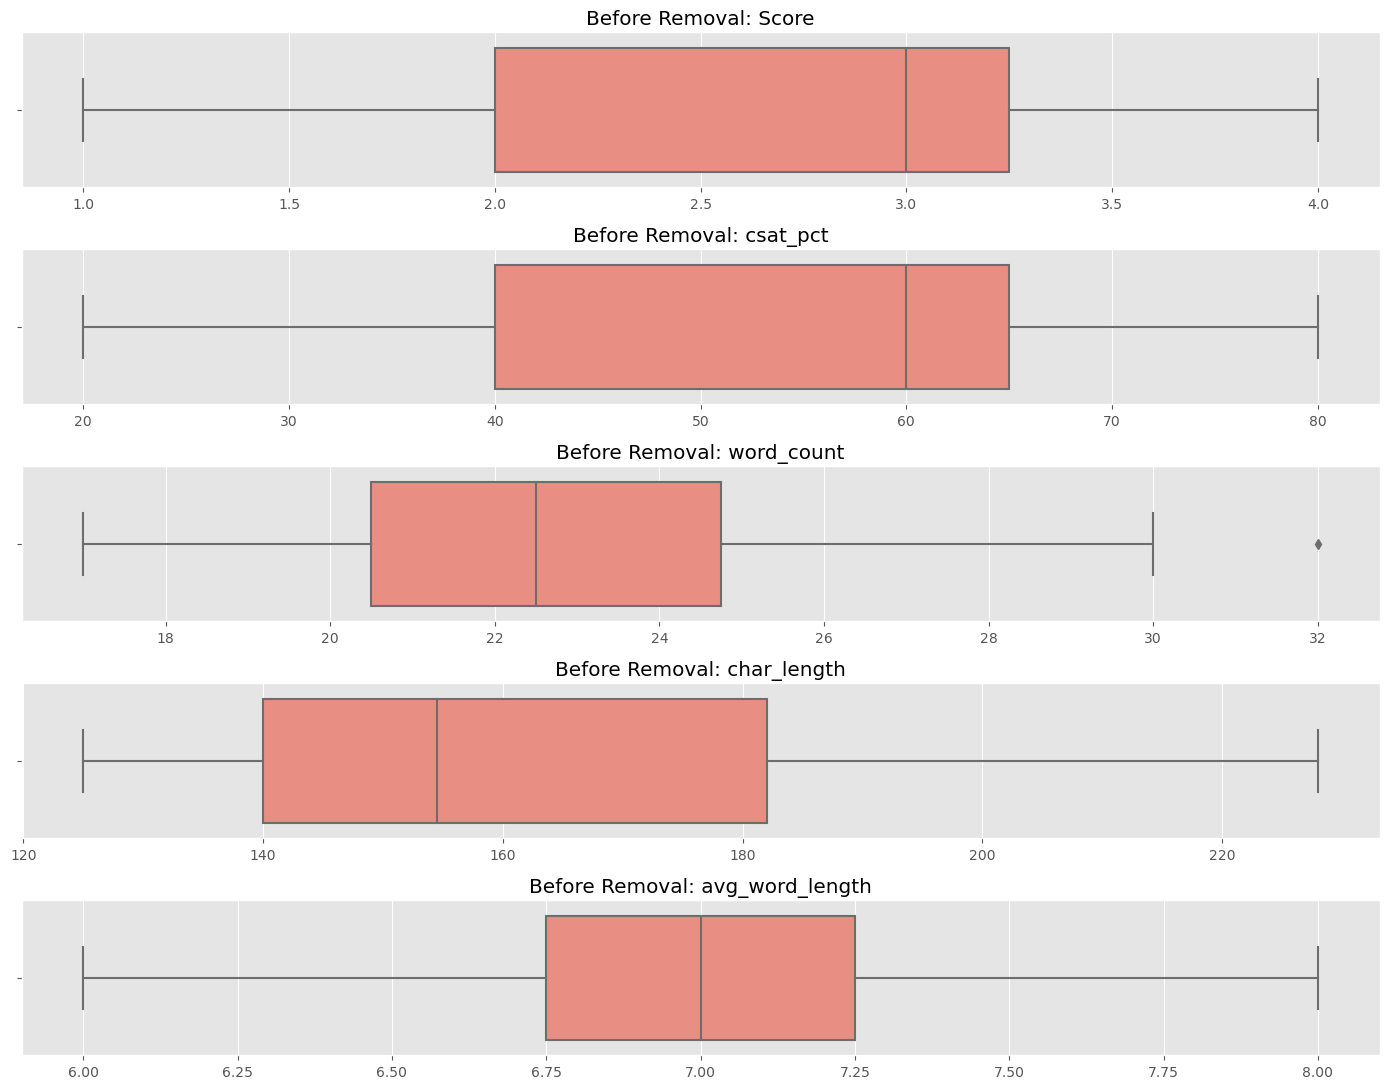

Records Before Removing Outliers: (12, 18)
Final Cleaned CSAT Shape: (10, 18)


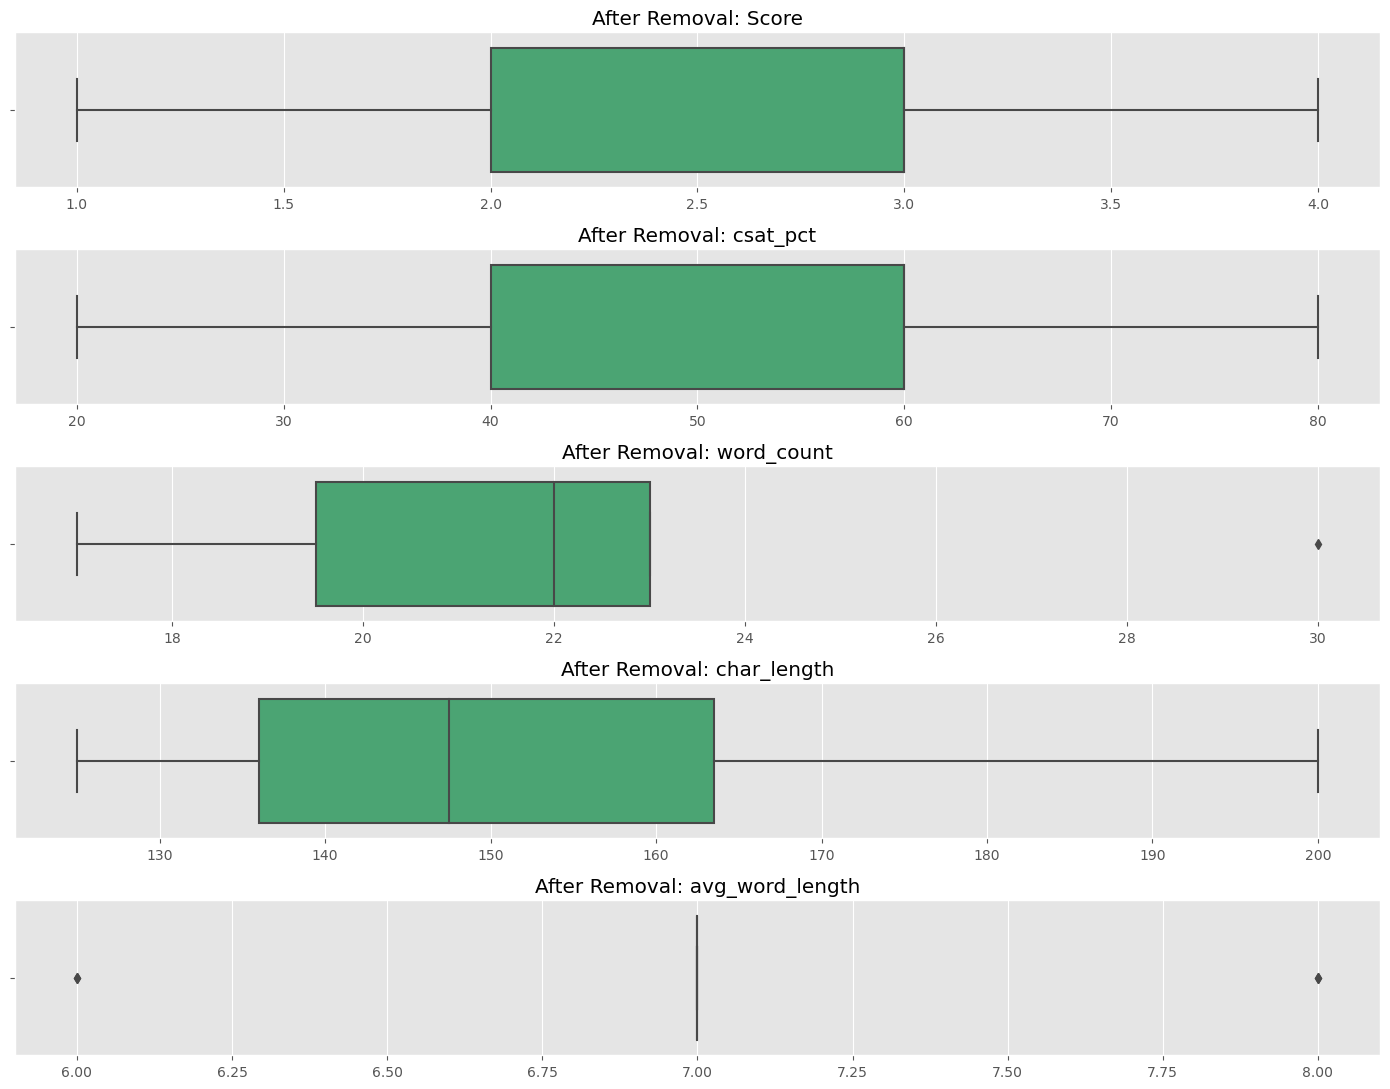

In [5]:
# %% [CSAT Step 5: Boxplots Before & After Outlier Removal]
int_cols = ["Score", "csat_pct", "word_count", "char_length", "avg_word_length"]

fig, axes = plt.subplots(len(int_cols), 1, figsize=(14, 11))
for row, column in enumerate(int_cols):
    sns.boxplot(x=df[column].values, ax=axes[row], color="salmon")
    axes[row].set_title(f"Before Removal: {column}")
plt.tight_layout()
plt.show()

outlier_columns = ["word_count", "char_length", "avg_word_length"]
print("Records Before Removing Outliers:", df.shape)
for col in outlier_columns:
    q1, q3 = df[col].quantile(0.25), df[col].quantile(0.75)
    iqr = q3 - q1
    if iqr > 0:
        df.drop(df[(df[col] < q1 - 1.5 * iqr) | (df[col] > q3 + 1.5 * iqr)].index, inplace=True)

df = df[df["Score"].between(1, 5)]
df.reset_index(drop=True, inplace=True)
print("Final Cleaned CSAT Shape:", df.shape)

fig, axes = plt.subplots(len(int_cols), 1, figsize=(14, 11))
for row, column in enumerate(int_cols):
    sns.boxplot(x=df[column].values, ax=axes[row], color="mediumseagreen")
    axes[row].set_title(f"After Removal: {column}")
plt.tight_layout()
plt.show()

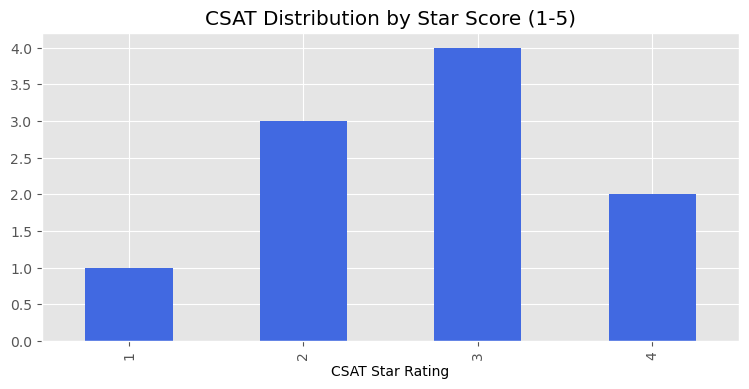

Example CSAT Text:
 arrival registration ease of access to hospital and clarity of external directional signs acceptable department workflow standard waiting time
Tokens[:10]: ['arrival', 'registration', 'ease', 'of', 'access', 'to', 'hospital', 'and', 'clarity', 'of']
POS Tags[:10]: [('arrival', 'JJ'), ('registration', 'NN'), ('ease', 'NN'), ('of', 'IN'), ('access', 'NN'), ('to', 'TO'), ('hospital', 'NN'), ('and', 'CC'), ('clarity', 'NN'), ('of', 'IN')]


In [6]:
# %% [CSAT Step 6: Quick EDA & Basic NLTK]
ax = df["Score"].value_counts().sort_index().plot(
    kind="bar", title="CSAT Distribution by Star Score (1-5)", figsize=(9, 4), color="royalblue"
)
ax.set_xlabel("CSAT Star Rating")
plt.show()

example = df["Text"].iloc[0]
print("Example CSAT Text:\n", example)
tokens = nltk.word_tokenize(example)
print("Tokens[:10]:", tokens[:10])
print("POS Tags[:10]:", nltk.pos_tag(tokens)[:10])

In [7]:
# %% [CSAT Step 7: Leak-Free CSAT Augmentation]
df["polarity_risk"] = np.where(
    df["Score"] >= 4, "Positive",
    np.where(df["Score"] == 3, "Neutral", "Negative")
)

smart_csat_corpus = [
    # --- SATISFIED (Positive: 4-5) ---
    ("OPD", "ease of scheduling outpatient appointment was excellent and staff were courteous 😍", 5, "Positive"),
    ("Medical", "physician consultation was thorough and treatment explanation was very clear 😊", 5, "Positive"),
    ("Nursing", "nursing care in ward was attentive polite and very supportive 👍", 5, "Positive"),
    ("Laboratory", "blood sample collection was painless and test reports were delivered fast", 5, "Positive"),
    ("Pharmacy", "pharmacy staff dispensed medicines quickly and explained dosage clearly", 5, "Positive"),
    ("Housekeeping", "patient room and washroom cleanliness were spotless and hygienic", 5, "Positive"),
    ("Radiology", "ultrasound and x ray technicians were helpful and process was smooth", 4, "Positive"),
    ("Billing", "discharge billing and insurance desk process was quick and transparent", 4, "Positive"),
    ("Dietary", "hospital meals were served warm hygienic and on time", 4, "Positive"),
    ("Admission", "front desk admission and room allotment were completed without delay", 5, "Positive"),
    ("OPD", "short waiting time at clinic and helpful coordinator", 4, "Positive"),
    ("Medical", "specialist doctor listened patiently and gave effective care", 5, "Positive"),
    ("Nursing", "night duty nurses checked vitals on time and were kind", 5, "Positive"),
    ("Laboratory", "well organized diagnostic counter and timely SMS report alert", 4, "Positive"),
    ("Housekeeping", "regular mopping and clean bedsheets maintained in ward", 4, "Positive"),

    # --- NEUTRAL (Average: 3) ---
    ("OPD", "outpatient registration was average took twenty five minutes in queue 😐", 3, "Neutral"),
    ("Medical", "doctor consultation was routine and brief standard follow up", 3, "Neutral"),
    ("Nursing", "nursing response was okay had to call twice for water", 3, "Neutral"),
    ("Laboratory", "laboratory service was normal report delivery took a few hours", 3, "Neutral"),
    ("Pharmacy", "pharmacy waiting time was moderate during peak afternoon hour", 3, "Neutral"),
    ("Housekeeping", "room cleanliness was acceptable though bathroom soap needed refill", 3, "Neutral"),
    ("Radiology", "scan process was standard waited twenty minutes outside room", 3, "Neutral"),
    ("Billing", "billing counter took forty minutes normal discharge crowd", 3, "Neutral"),
    ("Dietary", "food quality was average standard hospital diet served", 3, "Neutral"),
    ("Admission", "admission process was fair moderate wait for room readiness", 3, "Neutral"),
    ("OPD", "token display worked fine normal clinic waiting time", 3, "Neutral"),
    ("Pharmacy", "medicine billing was okay one syrup was out of stock", 3, "Neutral"),
    ("Laboratory", "routine blood work completed in acceptable time frame", 3, "Neutral"),
    ("Housekeeping", "corridor was reasonably clean standard maintenance", 3, "Neutral"),
    ("Billing", "satisfactory billing explanation neither fast nor slow", 3, "Neutral"),

    # --- DISSATISFIED (Negative: 1-2) ---
    ("OPD", "waited two hours past appointment slot dissatisfied with clinic scheduling 😡", 1, "Negative"),
    ("Medical", "doctor rushed consultation in two minutes and ignored our questions", 2, "Negative"),
    ("Nursing", "nurses did not respond to call bell while patient was in severe pain 😢", 1, "Negative"),
    ("Laboratory", "lab misplaced sample and delayed urgent blood report all day 👎", 1, "Negative"),
    ("Pharmacy", "pharmacy counter was super slow waited fifty minutes in queue", 2, "Negative"),
    ("Housekeeping", "washroom was dirty smelly and trash bin was overflowing", 1, "Negative"),
    ("Radiology", "waited three hours for MRI scan with no update from reception", 1, "Negative"),
    ("Billing", "final discharge bill took four hours and cashier was rude", 1, "Negative"),
    ("Dietary", "food was served cold and dietary staff were unhelpful", 2, "Negative"),
    ("Admission", "long delay in room allotment despite prior booking confirmation", 2, "Negative"),
    ("OPD", "crowded waiting hall and rude behavior at registration desk", 1, "Negative"),
    ("Pharmacy", "wrong medicine billed at pharmacy and slow refund process", 2, "Negative"),
    ("Laboratory", "long queue at blood collection counter and unorganized token system", 2, "Negative"),
    ("Housekeeping", "stained bedsheet and leaking tap in inpatient bathroom", 2, "Negative"),
    ("Billing", "confusing insurance clearance and poor communication at billing", 1, "Negative"),
]

aug_csat_rows = []
for aspect, raw_t, sc, pol in smart_csat_corpus:
    clean_t = clean_and_expand_text(f"{aspect} {raw_t}")
    aug_csat_rows.append({
        "Aspect": aspect,
        "Score": sc,
        "csat_pct": sc * 20,
        "Text": clean_t,
        "word_count": len(clean_t.split()),
        "char_length": len(clean_t),
        "avg_word_length": round(len(clean_t) / max(1, len(clean_t.split()))),
        "polarity_risk": pol,
    })

cols_keep = ["Aspect", "Score", "csat_pct", "Text", "word_count", "char_length", "avg_word_length", "polarity_risk"]
df_full = pd.concat([df[cols_keep], pd.DataFrame(aug_csat_rows)], ignore_index=True)
df_full.drop_duplicates(subset=["Text"], inplace=True)
df_full.reset_index(drop=True, inplace=True)

print("✅ CSAT Step 7 Complete: Leak-Free CSAT Corpus Shape:", df_full.shape)
print(df_full["polarity_risk"].value_counts())

✅ CSAT Step 7 Complete: Leak-Free CSAT Corpus Shape: (55, 8)
Neutral     19
Negative    19
Positive    17
Name: polarity_risk, dtype: int64


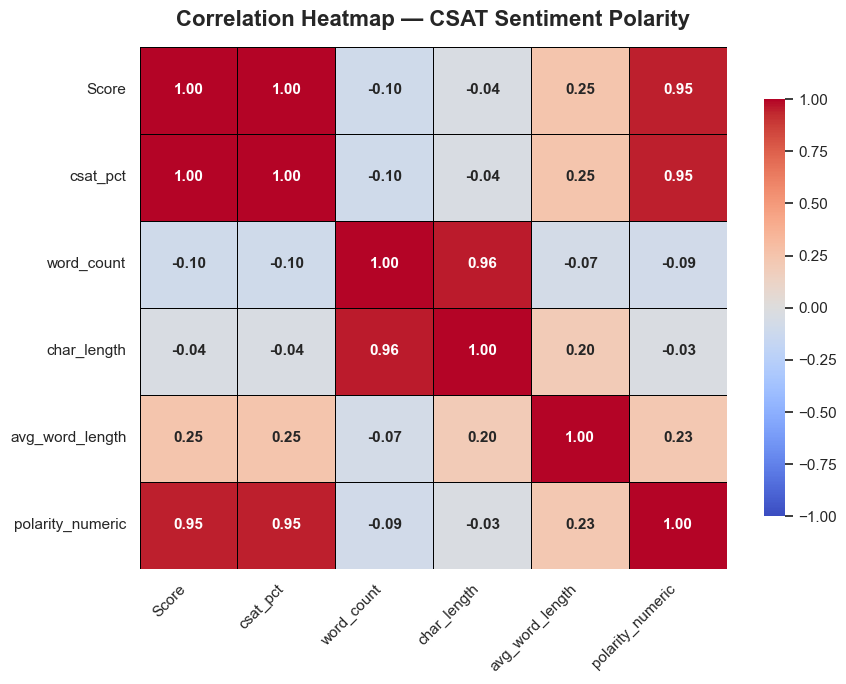

In [8]:
# %% [CSAT Step 8: Correlation Heatmap]
num_features = ["Score", "csat_pct", "word_count", "char_length", "avg_word_length"]
df_full["polarity_numeric"] = df_full["polarity_risk"].map({"Negative": 0, "Neutral": 1, "Positive": 2})

corr_matrix = df_full[num_features + ["polarity_numeric"]].corr()
plt.figure(figsize=(9, 7))
sns.set_theme(style="white")
sns.heatmap(
    corr_matrix, annot=True, fmt=".2f", cmap="coolwarm",
    vmin=-1, vmax=1, linewidths=0.5, linecolor="black",
    cbar_kws={"shrink": 0.8}, annot_kws={"size": 11, "weight": "bold"}
)
plt.title("Correlation Heatmap — CSAT Sentiment Polarity", fontsize=16, fontweight="bold", pad=15)
plt.xticks(rotation=45, ha="right")
plt.yticks(rotation=0)
plt.tight_layout()
plt.show()

In [9]:
# %% [CSAT Step 9: Train & Compare Regularized Classical ML Models + Overfitting Check]
nlp_feature_union = FeatureUnion([
    ("word_tfidf", Pipeline([
        ("tfidf", TfidfVectorizer(analyzer="word", ngram_range=(1, 2), min_df=2, max_df=0.90, sublinear_tf=True)),
        ("chi2", SelectPercentile(chi2, percentile=75))
    ])),
    ("char_tfidf", Pipeline([
        ("tfidf", TfidfVectorizer(analyzer="char_wb", ngram_range=(3, 4), min_df=3, max_df=0.90, sublinear_tf=True)),
        ("chi2", SelectPercentile(chi2, percentile=65))
    ])),
    ("domain_signals", Pipeline([
        ("ext", HospitalDomainFeatureExtractor()),
        ("scale", MinMaxScaler())
    ]))
])

le_polarity = LabelEncoder()
y = le_polarity.fit_transform(df_full["polarity_risk"])
X = df_full["Text"]

lr_clf = LogisticRegression(C=0.45, penalty="l2", class_weight="balanced", max_iter=1000, random_state=42)
nb_clf = ComplementNB(alpha=0.35, norm=True)
svm_clf = CalibratedClassifierCV(LinearSVC(C=0.25, class_weight="balanced", random_state=42), cv=3)
nb_cal = CalibratedClassifierCV(ComplementNB(alpha=0.35, norm=True), cv=3)

voting_clf = VotingClassifier(
    estimators=[("lr", lr_clf), ("nb", nb_cal), ("svm", svm_clf)],
    voting="soft", weights=[2, 2, 3]
)

models = {
    "Logistic Regression": lr_clf,
    "Complement Naive Bayes": nb_clf,
    "Linear SVM": svm_clf,
    "Classical Soft-Voting Ensemble": voting_clf
}

results, performance_list, overfit_check_list = {}, [], []
skf = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)

for name, clf in models.items():
    pipe = Pipeline([("features", nlp_feature_union), ("classifier", clf)])
    pipe.fit(X, y)
    train_acc = accuracy_score(y, pipe.predict(X))
    cv_preds = cross_val_predict(pipe, X, y, cv=skf)

    test_acc = accuracy_score(y, cv_preds)
    test_prec = precision_score(y, cv_preds, average="macro", zero_division=0)
    test_rec = recall_score(y, cv_preds, average="macro", zero_division=0)
    test_f1 = f1_score(y, cv_preds, average="macro", zero_division=0)
    gap = train_acc - test_acc

    results[name] = {"pipeline": pipe, "cv_preds": cv_preds}
    performance_list.append({
        "Model": name, "Accuracy": round(test_acc, 4),
        "Precision": round(test_prec, 4), "Recall": round(test_rec, 4), "F1_Score": round(test_f1, 4)
    })
    overfit_check_list.append({
        "Model": name, "Train_Accuracy": round(train_acc, 4),
        "Test_CV_Accuracy": round(test_acc, 4), "Overfit_Gap": round(gap, 4),
        "Fit_Status": "✅ Good Fit" if gap <= 0.12 else "⚠️ Mild Overfit"
    })

performance_df = pd.DataFrame(performance_list).sort_values(by="F1_Score", ascending=False)
overfit_df = pd.DataFrame(overfit_check_list).sort_values(by="Test_CV_Accuracy", ascending=False)

print("=== CSAT MODEL PERFORMANCE ===")
display(performance_df)
print("\n=== CSAT OVERFITTING CHECK ===")
display(overfit_df)

=== CSAT MODEL PERFORMANCE ===


,Model,Accuracy,Precision,Recall,F1_Score
1,Complement Naive Bayes,0.8727,0.8743,0.8731,0.8724
2,Linear SVM,0.8545,0.8581,0.8514,0.8536
3,Classical Soft-Voting Ensemble,0.8545,0.8581,0.8514,0.8536
0,Logistic Regression,0.8364,0.8382,0.8338,0.8356



=== CSAT OVERFITTING CHECK ===


,Model,Train_Accuracy,Test_CV_Accuracy,Overfit_Gap,Fit_Status
1,Complement Naive Bayes,0.9636,0.8727,0.0909,✅ Good Fit
2,Linear SVM,0.9818,0.8545,0.1273,⚠️ Mild Overfit
3,Classical Soft-Voting Ensemble,0.9818,0.8545,0.1273,⚠️ Mild Overfit
0,Logistic Regression,0.9818,0.8364,0.1455,⚠️ Mild Overfit


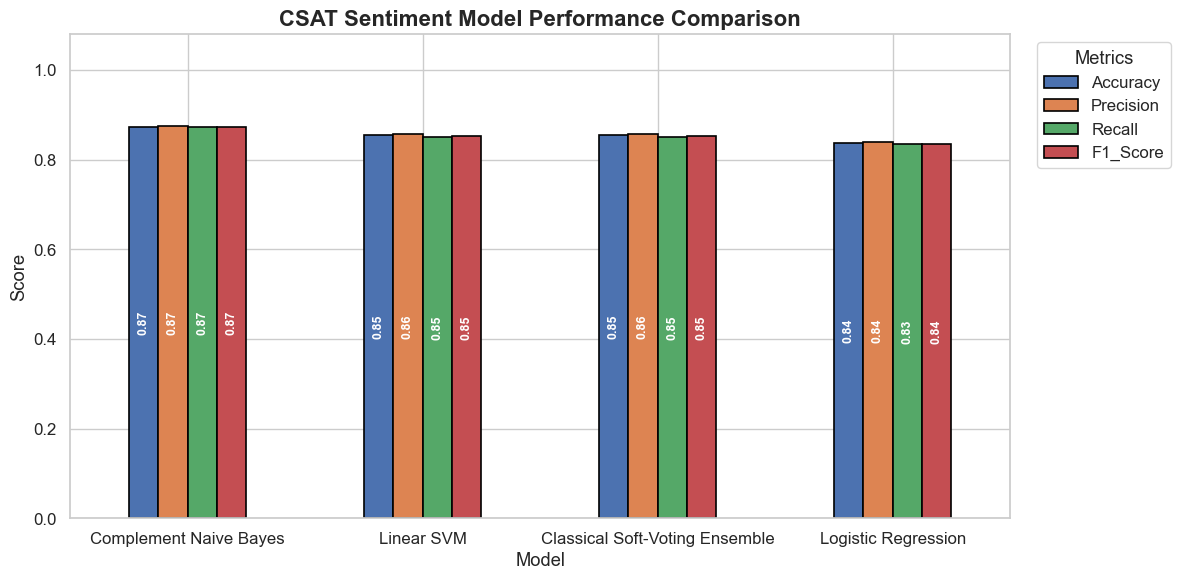

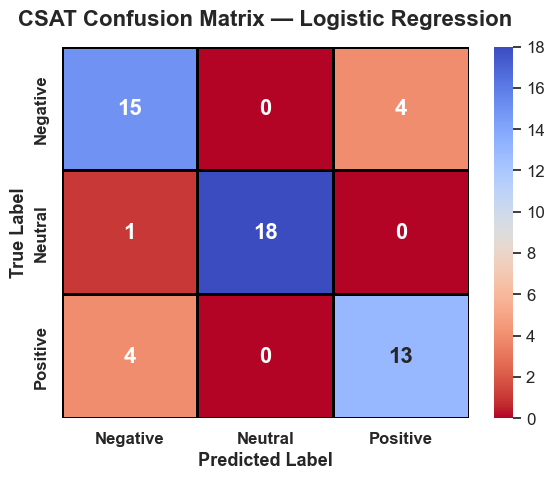

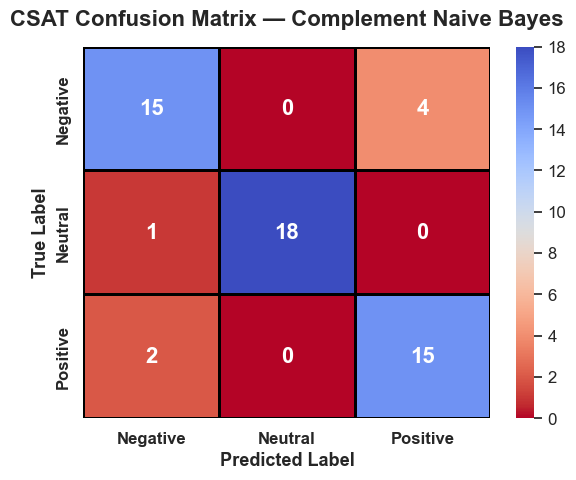

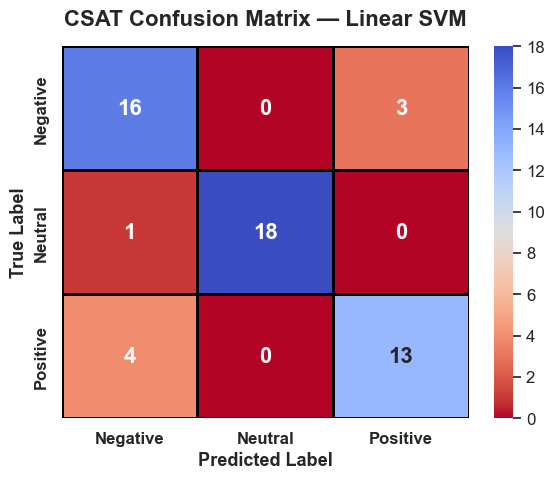

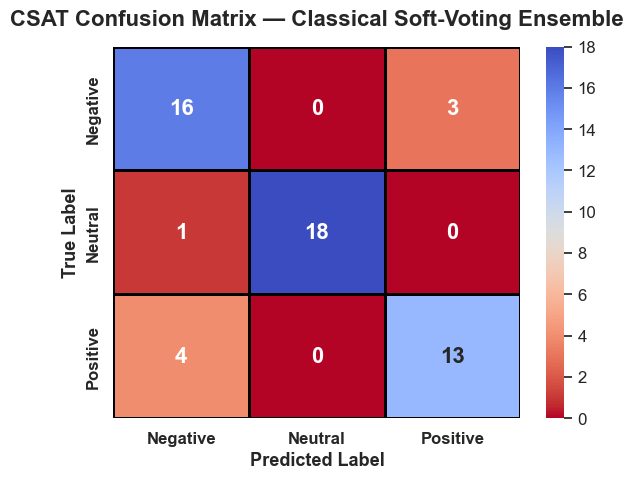

In [10]:
# %% [CSAT Step 10: Model Performance Bar Chart & Confusion Matrices]
sns.set(style="whitegrid", font_scale=1.1)
ax = performance_df.set_index("Model").plot(kind="bar", figsize=(12, 6), edgecolor="black", linewidth=1.2)
plt.title("CSAT Sentiment Model Performance Comparison", fontsize=16, weight="bold")
plt.ylabel("Score")
plt.ylim(0, 1.08)
plt.xticks(rotation=0)
plt.legend(title="Metrics", bbox_to_anchor=(1.02, 1), loc="upper left")

for p in ax.patches:
    val = p.get_height()
    if val > 0.05:
        ax.text(p.get_x() + p.get_width() / 2., val / 2., f"{val:.2f}", ha="center", va="center", rotation=90, color="white", fontsize=9, fontweight="bold")
plt.tight_layout()
plt.show()

class_labels = list(le_polarity.classes_)
tick_locs = np.arange(len(class_labels)) + 0.5
for name, model_info in results.items():
    cm = confusion_matrix(y, model_info["cv_preds"], labels=np.arange(len(class_labels)))
    plt.figure(figsize=(6, 5))
    sns.heatmap(cm, annot=True, fmt="d", cmap="coolwarm_r", linewidths=2, linecolor="black", annot_kws={"size": 16, "weight": "bold"})
    plt.title(f"CSAT Confusion Matrix — {name}", fontsize=16, fontweight="bold", pad=15)
    plt.xlabel("Predicted Label", fontsize=13, fontweight="bold")
    plt.ylabel("True Label", fontsize=13, fontweight="bold")
    plt.xticks(ticks=tick_locs, labels=class_labels, fontsize=12, fontweight="bold")
    plt.yticks(ticks=tick_locs, labels=class_labels, fontsize=12, fontweight="bold")
    plt.tight_layout()
    plt.show()

In [11]:
# %% [CSAT Step 11: Save Winning CSAT Model to csat_best_model.pkl]
best_model_name = performance_df.iloc[0]["Model"]
best_pipeline = results[best_model_name]["pipeline"]
best_pipeline.fit(X, y)

CSAT_PKL = r"C:\Users\91910\OneDrive\Desktop\mrico\csat_best_model.pkl"
joblib.dump({
    "polarity_pipeline": best_pipeline,
    "polarity_encoder": le_polarity,
    "polarity_winner": best_model_name,
    "benchmark_table": performance_df.to_dict(orient="records"),
}, CSAT_PKL)
print(f"🏆 Saved Winning CSAT Model '{best_model_name}' to:\n   {CSAT_PKL}")

🏆 Saved Winning CSAT Model 'Complement Naive Bayes' to:
   C:\Users\91910\OneDrive\Desktop\mrico\csat_best_model.pkl
